# 04 - Random Forest

Our implementation is in `src/random_forest.py` (it uses our own decision tree). What we try:
1. **number of trees**
2. **features tried at each split** (`max_features`)
3. **maximum depth**
4. **minimum samples per leaf**

and we compare the forest with the single tree from notebook 03.

`N_JOBS` = how many CPU cores build trees in parallel. The result is identical for any value;
lower it if your computer runs out of memory.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_split, N_CLASSES, SEED
from src.random_forest import RandomForestClassifier
from src.decision_tree import DecisionTreeClassifier
from src.utils import COLORS, accuracy, Timer, save_table, save_figure, save_predictions, load_predictions, set_seed

set_seed()
N_JOBS = 3
N_TREES = 400        # size of the main forests
SWEEP_TREES = 60     # smaller forests for the parameter sweeps, to keep the run time reasonable
splits = {task: get_split(task) for task in ("image", "sentiment")}

## 1. Number of trees
The trees are independent, so "the first n trees of a 400-tree forest" is exactly a forest with
n trees. One forest per task gives the whole curve.

A 400-tree image forest takes a lot of memory (every node of every tree stores 50 class
probabilities), so we save what we need from each forest right away and then delete it.

In [2]:
FINAL = dict(n_estimators=N_TREES, max_features="sqrt", max_depth=None, min_samples_leaf=1)
rows, final_info, forest_imp = [], {}, {}
for task, (Xtr, ytr, Xva, yva) in splits.items():
    with Timer() as t:
        rf = RandomForestClassifier(n_estimators=N_TREES, max_features="sqrt", random_state=SEED,
                                    n_jobs=N_JOBS).fit(Xtr, ytr, N_CLASSES[task])
    print(f"{task}: {N_TREES} trees in {t.seconds:.0f}s, OOB accuracy {rf.oob_score:.4f}")
    for n, proba in enumerate(rf.staged_predict_proba(Xva), start=1):
        rows.append(dict(task=task, n_trees=n, val_acc=accuracy(yva, proba.argmax(1))))
    # this default forest turns out to be our final one (section 5), so save its predictions now
    with Timer() as t_pred:
        proba = rf.predict_proba(Xva)
    final_info[task] = dict(model="Random Forest", config=FINAL, val_acc=accuracy(yva, proba.argmax(1)),
                            train_acc=accuracy(ytr, rf.predict(Xtr)), oob_acc=rf.oob_score,
                            fit_seconds=t.seconds, predict_seconds=t_pred.seconds)
    save_predictions(task, "rf", proba.argmax(1), proba, final_info[task])
    forest_imp[task] = rf.feature_importances      # keep it before the forest is deleted
    del rf
n_trees = pd.DataFrame(rows)
save_table(n_trees, "rf_n_trees")
n_trees[n_trees.n_trees.isin([1, 5, 10, 25, 50, 100, 200, 300, 400])].pivot(index="n_trees", columns="task", values="val_acc").round(4)

image: 400 trees in 355s, OOB accuracy 0.3143
sentiment: 400 trees in 75s, OOB accuracy 0.6094


task,image,sentiment
n_trees,,
1,0.0798,0.4038
5,0.1035,0.4792
10,0.1328,0.5004
25,0.1932,0.5529
50,0.2490,0.5812
100,0.2932,0.5946
200,0.3355,0.6029
300,0.3530,0.6038
400,0.3662,0.6029


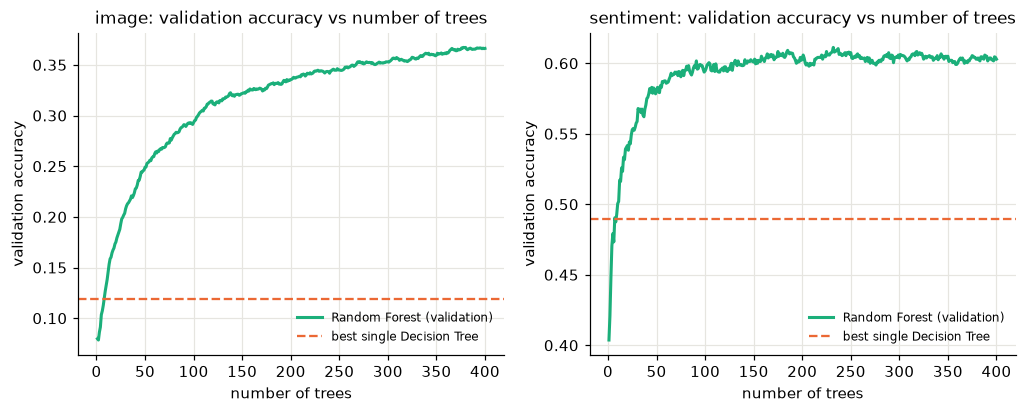

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, splits):
    r = n_trees[n_trees.task == task]
    ax.plot(r.n_trees, r.val_acc, color=COLORS[2], label="Random Forest (validation)")
    ax.axhline(load_predictions(task, "dt")[2]["val_acc"], color=COLORS[1], linestyle="--",
               linewidth=1.5, label="best single Decision Tree")
    ax.set_xlabel("number of trees")
    ax.set_ylabel("validation accuracy")
    ax.set_title(f"{task}: validation accuracy vs number of trees")
    ax.legend(fontsize=8)
save_figure(fig, "04_rf_n_trees")
plt.show()

* **Sentiment:** one tree gets about 40%; the forest climbs fast and levels off around 60% after
  100-150 trees.
* **Images:** one tree gets 8%, 400 trees reach 36.6%, and accuracy is *still* going up. With 50
  classes and weak single features each tree is a very noisy voter, so many votes are needed.
* **OOB accuracy** uses, for each training row, only the ~37% of trees that did not see it (about
  150 trees), which is why on images it is lower than the validation accuracy of all 400 trees.

## 2-4. Features per split, depth, leaf size (60-tree forests)

In [4]:
def sweep(param, values):
    rows = []
    for task, (Xtr, ytr, Xva, yva) in splits.items():
        for v in values:
            config = dict(max_features="sqrt", max_depth=None, min_samples_leaf=1)
            config[param] = v
            with Timer() as t:
                rf = RandomForestClassifier(n_estimators=SWEEP_TREES, random_state=SEED, n_jobs=N_JOBS,
                                            **config).fit(Xtr, ytr, N_CLASSES[task])
            rows.append(dict(task=task, param=param, value=str(v),
                             train_acc=accuracy(ytr, rf.predict(Xtr)), val_acc=accuracy(yva, rf.predict(Xva)),
                             oob_acc=rf.oob_score, fit_s=round(t.seconds, 1)))
            print(f"{task:9s} {param}={v}: val {rows[-1]['val_acc']:.4f} ({t.seconds:.0f}s)")
    return pd.DataFrame(rows)

max_features = sweep("max_features", ["log2", "sqrt", 0.1, 0.25])
max_features.round(4)

image     max_features=log2: val 0.2305 (44s)
image     max_features=sqrt: val 0.2625 (52s)
image     max_features=0.1: val 0.2685 (76s)
image     max_features=0.25: val 0.2545 (203s)
sentiment max_features=log2: val 0.5637 (11s)
sentiment max_features=sqrt: val 0.5858 (12s)
sentiment max_features=0.1: val 0.5725 (17s)
sentiment max_features=0.25: val 0.5804 (28s)


,task,param,value,train_acc,val_acc,oob_acc,fit_s
0,image,max_features,log2,1.0,0.2305,0.1599,44.3
1,image,max_features,sqrt,1.0,0.2625,0.1841,52.3
2,image,max_features,0.1,1.0,0.2685,0.1986,75.8
3,image,max_features,0.25,1.0,0.2545,0.2011,202.8
4,sentiment,max_features,log2,1.0,0.5638,0.5305,11.4
5,sentiment,max_features,sqrt,1.0,0.5858,0.5369,12.0
6,sentiment,max_features,0.1,1.0,0.5725,0.5567,17.2
7,sentiment,max_features,0.25,1.0,0.5804,0.5521,27.6


Too few features per split (log2, about 8) makes every tree too weak. Between sqrt(d) and 10-25%
of the features the differences are small (checked at full size in section 5).

In [5]:
max_depth = sweep("max_depth", [5, 10, 20, 30, None])
max_depth.round(4)

image     max_depth=5: val 0.1393 (3s)
image     max_depth=10: val 0.1750 (6s)
image     max_depth=20: val 0.2213 (23s)
image     max_depth=30: val 0.2425 (34s)
image     max_depth=None: val 0.2625 (55s)
sentiment max_depth=5: val 0.5675 (3s)
sentiment max_depth=10: val 0.5842 (7s)
sentiment max_depth=20: val 0.5771 (14s)
sentiment max_depth=30: val 0.5858 (15s)
sentiment max_depth=None: val 0.5858 (14s)


,task,param,value,train_acc,val_acc,oob_acc,fit_s
0,image,max_depth,5,0.1924,0.1393,0.1181,2.8
1,image,max_depth,10,0.5979,0.1750,0.1451,6.0
2,image,max_depth,20,0.9902,0.2212,0.1756,23.1
3,image,max_depth,30,0.9999,0.2425,0.1829,34.4
4,image,max_depth,None,1.0000,0.2625,0.1841,55.2
5,sentiment,max_depth,5,0.6514,0.5675,0.5622,3.2
6,sentiment,max_depth,10,0.9752,0.5842,0.5658,6.6
7,sentiment,max_depth,20,1.0000,0.5771,0.5332,13.7
8,sentiment,max_depth,30,1.0000,0.5858,0.5362,14.7
9,sentiment,max_depth,None,1.0000,0.5858,0.5369,14.3


Unlike a single tree, the forest wants **fully grown** trees (images: 13.9% at depth 5 vs 26.3%
unlimited). Each deep tree overfits (low bias, high variance), and averaging many different trees
cancels much of the variance while keeping the low bias.

In [6]:
min_leaf = sweep("min_samples_leaf", [1, 3, 10])
min_leaf.round(4)

image     min_samples_leaf=1: val 0.2625 (57s)
image     min_samples_leaf=3: val 0.2607 (35s)
image     min_samples_leaf=10: val 0.2560 (18s)
sentiment min_samples_leaf=1: val 0.5858 (11s)
sentiment min_samples_leaf=3: val 0.5800 (10s)
sentiment min_samples_leaf=10: val 0.5850 (6s)


,task,param,value,train_acc,val_acc,oob_acc,fit_s
0,image,min_samples_leaf,1,1.0000,0.2625,0.1841,56.7
1,image,min_samples_leaf,3,0.9999,0.2608,0.1991,34.7
2,image,min_samples_leaf,10,0.9859,0.2560,0.1971,17.6
3,sentiment,min_samples_leaf,1,1.0000,0.5858,0.5369,11.2
4,sentiment,min_samples_leaf,3,0.9998,0.5800,0.5559,9.8
5,sentiment,min_samples_leaf,10,0.9829,0.5850,0.5684,5.6


In [7]:
save_table(pd.concat([max_features, max_depth, min_leaf]), "rf_sweeps")

Leaf size has a small effect (under 1 point): there is little to gain by restricting the trees.

## 5. Final forest
The sweeps used 60-tree forests, where differences under ~1 point can be noise. The only setting
that beat the defaults was `max_features=0.1` on images, so we rebuild it at full size (400 trees).

In [8]:
Xtr, ytr, Xva, yva = splits["image"]
with Timer() as t:
    rf_01 = RandomForestClassifier(n_estimators=N_TREES, max_features=0.1, random_state=SEED,
                                   n_jobs=N_JOBS).fit(Xtr, ytr, 50)
print(f"image, max_features=0.1:  val {accuracy(yva, rf_01.predict(Xva)):.4f}, OOB {rf_01.oob_score:.4f} ({t.seconds:.0f}s)")
print(f"image, max_features=sqrt: val {final_info['image']['val_acc']:.4f}, OOB {final_info['image']['oob_acc']:.4f}")
del rf_01

image, max_features=0.1:  val 0.3563, OOB 0.3098 (447s)
image, max_features=sqrt: val 0.3663, OOB 0.3143


At full size sqrt(d) wins (36.6% vs 35.6%), so the final forest for both tasks is the default:
**400 trees, max_features = sqrt, no depth limit, min_samples_leaf = 1**.

## 6. Forest vs single tree
The forest's *training* accuracy is ~100% because every training row was seen by most trees.
What matters is accuracy on unseen data (validation and OOB).

In [9]:
rows = []
for task in splits:
    dt = load_predictions(task, "dt")[2]
    rf = final_info[task]
    rows.append(dict(task=task, model="Decision Tree", train_acc=dt["train_acc"], val_acc=dt["val_acc"]))
    rows.append(dict(task=task, model="Random Forest", train_acc=rf["train_acc"], val_acc=rf["val_acc"],
                     oob_acc=rf["oob_acc"]))
comparison = pd.DataFrame(rows)
comparison["gap"] = comparison.train_acc - comparison.val_acc
comparison.round(4)

,task,model,train_acc,val_acc,oob_acc,gap
0,image,Decision Tree,0.1733,0.1192,NaN,0.0541
1,image,Random Forest,1.0000,0.3662,0.3143,0.6338
2,sentiment,Decision Tree,0.6160,0.4896,NaN,0.1265
3,sentiment,Random Forest,1.0000,0.6029,0.6094,0.3971


The forest beats the best single tree by **+24.7 points on images** (36.6% vs 11.9%) and **+11.3
points on sentiment** (60.3% vs 49.0%). Its train-validation gap looks bigger only because its
training accuracy is 100%; its error on unseen data is far lower. Averaging removes most of the
variance that makes a single deep tree generalize badly.

## 7. Feature importance: single tree vs forest average
The two vectors come from trees of very different size, so they answer slightly different questions.
The single tree from notebook 03 tries all features but stops at `min_samples_leaf=50`, so it makes
only 143 (sentiment) and 235 (image) splits, and only 120 of the 768 sentiment features (138 of the
500 image ones) become nonzero.
Each forest tree grows to pure leaves on a bootstrap sample and tries only sqrt(d) features per node
(27 on sentiment, 22 on image). Averaging 400 of them spreads the credit over far more splits, so the
ranking is flatter and not tied to one tree's top levels.


In [10]:
TOP = 10
imp_rows, overlap = [], {}
for task, (Xtr, ytr, _, _) in splits.items():
    # the single tree of notebook 03, rebuilt from the config it saved
    conf = load_predictions(task, "dt")[2]["config"]
    dt_imp = DecisionTreeClassifier(**conf).fit(Xtr, ytr, N_CLASSES[task]).feature_importances
    fi = forest_imp[task]
    common = set(np.argsort(-dt_imp)[:TOP]) & set(np.argsort(-fi)[:TOP])
    overlap[task] = f"{len(common)} / {TOP}"
    for rank, j in enumerate(np.argsort(-fi)[:TOP], start=1):
        imp_rows.append(dict(task=task, rank=rank, feature=f"f{j}",
                             forest=round(float(fi[j]), 4),
                             single_tree=round(float(dt_imp[j]), 4)))
importance = pd.DataFrame(imp_rows)
print("top-10 features shared by the single tree and the forest:", overlap)
importance


top-10 features shared by the single tree and the forest: {'image': '1 / 10', 'sentiment': '4 / 10'}


,task,rank,feature,forest,single_tree
0,image,1,f425,0.0049,0.0097
1,image,2,f319,0.0048,0.0203
2,image,3,f269,0.0044,0.0086
3,image,4,f153,0.0042,0.0000
4,image,5,f348,0.0041,0.0193
5,image,6,f152,0.0040,0.0100
6,image,7,f44,0.0040,0.0013
7,image,8,f196,0.0039,0.0216
8,image,9,f22,0.0038,0.0034
9,image,10,f15,0.0038,0.0049
